# Global Voices: word splits and sentence context

This notebook asks whether the words around a target word help explain the FlexiTokens split it receives. Each sentence containing the word is represented by counts of the other words in that sentence. K-means groups those contexts without seeing the FlexiTokens splits; the notebook compares the splits within each group afterwards.

The saved analysis covers English, Spanish, Russian, and Hindi, the languages available in the Global Voices language pairs used here. Clone the `global-voices-context-analysis` branch and open this notebook from that repository checkout. The included summaries and example analyses let the notebook run and show the results without the large SQLite database (about 5.6 GB). Without that database, interactive lookup is available for the saved example words only.

To analyze a new word, first build the database once. The public sentence dataset downloads automatically. The build also needs the FlexiTokens model checkpoint used for this analysis and several gigabytes of free disk space; it can take hours. From the repository root, run:

```bash
PYTHONPATH=flexitokens python3 -m src.eval.global_voices_contexts \
  --model-path /path/to/flexitokens/checkpoint \
  --revision 4cc20add371f246bb1559b543f8b0dea178a1803 \
  --languages en,es,ru,hi --time-limit-minutes 0 --batch-size 2
```

After it finishes, rerun the notebook and enter any word from one of the four languages in the lookup cell.

In [1]:
from pathlib import Path
import ast, importlib.util, json, os, sqlite3, sys, tempfile

missing = [name for name in ('scipy', 'sklearn') if importlib.util.find_spec(name) is None]
if missing:
    packages = ' '.join('scikit-learn' if name == 'sklearn' else name for name in missing)
    raise ModuleNotFoundError(
        f'This notebook kernel is {sys.executable} and is missing {", ".join(missing)}. '
        f'Install them into this notebook kernel with: '
        f'"{sys.executable}" -m pip install {packages}'
    )
os.environ.setdefault('MPLCONFIGDIR', str(Path(tempfile.gettempdir()) / 'mpl-global-voices'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / 'results/global_voices_context_analysis/language_coverage.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Clone the global-voices-context-analysis branch and open this notebook from that repository checkout.')
RESULTS_DIR = ROOT / 'results/global_voices_context_analysis'
DATABASE_PATH = Path(os.environ.get('GLOBAL_VOICES_ANALYSIS_DB', RESULTS_DIR / 'analysis.sqlite3'))
DATABASE_AVAILABLE = DATABASE_PATH.exists()
PROGRESS_PATH = RESULTS_DIR / 'progress.json'
MANIFEST_PATH = RESULTS_DIR / 'run_manifest.json'
WORD_SUMMARY_DIR = RESULTS_DIR / 'word_summaries'
LANGUAGES = ['en', 'es', 'ru', 'hi']
print('results folder:', RESULTS_DIR)
print('interactive database available:', DATABASE_AVAILABLE)
if not DATABASE_AVAILABLE:
    print('The saved corpus summaries and example analyses are available. A new word lookup needs the analysis SQLite database.')
print('run manifest:', json.loads(MANIFEST_PATH.read_text()) if MANIFEST_PATH.exists() else 'not recorded')

results folder: /Users/samarth.gaggar/Downloads/OSU Tokenization/flexitokens/results/global_voices_context_analysis
interactive database available: True
run manifest: {'created_at_utc': '2026-10-20T01:15:40.824112+00:00', 'dataset': 'sentence-transformers/parallel-sentences-global-voices', 'dataset_revision_requested': 'main', 'dataset_revision_resolved': '4cc20add371f246bb1559b543f8b0dea178a1803', 'configs_by_language': {'en': ['en-es', 'en-ru', 'en-hi'], 'es': ['en-es'], 'ru': ['en-ru'], 'hi': ['en-hi']}, 'dataset_columns': {'en': 'english', 'es': 'non_english', 'ru': 'non_english', 'hi': 'non_english'}, 'deduplication': 'exact sentence text within each language; English is the union of en-es, en-ru, en-hi', 'model_path': 'model_ckpts/_2025-05-03_14-43-31', 'model_file_size_bytes': 1507845606, 'model_file_mtime_ns': 1785063101000000000, 'model_config_sha256': '80e9751d938f0e534067a64afe14e673400af27c256dee2b66c54047b89a15e1', 'boundary_rule': 'sigmoid(boundary_logit) > 0.5', 'boundar

### Computation used for a word lookup

The code below is the notebook implementation of the lookup: it retrieves the selected word’s sentence occurrences, builds one count vector per sentence from the other words, clusters those vectors, and then calculates the split counts for each group. The split labels are not clustering inputs. The same implementation is also available as `flexitokens/src/eval/context_clusters.py` for command-line use.


In [2]:
#!/usr/bin/env python3
"""Explore whether similar sentence contexts align with word split patterns."""

import argparse
import json
import os
import sqlite3
from array import array
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import normalize


def load_language_occurrences(database_path, language):
    """Load saved word spans and their sentence text for one language."""
    with sqlite3.connect(database_path) as connection:
        return pd.read_sql_query(
            """SELECT o.language, o.sentence_id, s.source_config, s.source_row,
                      s.text AS sentence, o.char_start, o.char_end, o.surface_word,
                      o.lowercase_word, o.boundary_signature, o.segmentation_display,
                      o.piece_count, o.has_intra_character_boundary
               FROM occurrences AS o
               JOIN sentences AS s USING(language, sentence_id)
               WHERE o.language = ?
               ORDER BY o.sentence_id, o.char_start""",
            connection,
            params=(language,),
        )


def summarize_words(occurrences, min_frequency=1):
    """Count frequency and distinct observed split patterns for each word."""
    if occurrences.empty:
        return pd.DataFrame(columns=["word", "occurrence_frequency", "sentence_frequency",
                                     "unique_segmentations", "dominant_segmentation",
                                     "dominant_count", "dominant_share"])
    rows = []
    for word, group in occurrences.groupby("lowercase_word", sort=True):
        pattern_counts = group["boundary_signature"].value_counts()
        if len(group) < min_frequency:
            continue
        dominant_signature = pattern_counts.index[0]
        display = group.loc[group["boundary_signature"] == dominant_signature,
                            "segmentation_display"].iloc[0]
        rows.append({
            "word": word,
            "occurrence_frequency": len(group),
            "sentence_frequency": group["sentence_id"].nunique(),
            "unique_segmentations": len(pattern_counts),
            "dominant_segmentation": display,
            "dominant_count": int(pattern_counts.iloc[0]),
            "dominant_share": float(pattern_counts.iloc[0] / len(group)),
        })
    return pd.DataFrame(rows)


def summarize_language_words(database_path, language, min_frequency=1):
    """Return per-word occurrence and distinct-split counts for corpus charts."""
    with sqlite3.connect(database_path) as connection:
        frequencies = pd.read_sql_query(
            """SELECT lowercase_word AS word, COUNT(*) AS occurrence_frequency
               FROM occurrences WHERE language=?
               GROUP BY lowercase_word HAVING COUNT(*) >= ?
               ORDER BY lowercase_word""",
            connection, params=(language, min_frequency),
        )
        split_counts = pd.read_sql_query(
            """SELECT lowercase_word AS word, COUNT(*) AS unique_segmentations
               FROM (
                   SELECT lowercase_word, boundary_signature
                   FROM occurrences WHERE language=?
                   GROUP BY lowercase_word, boundary_signature
               )
               GROUP BY lowercase_word
               ORDER BY lowercase_word""",
            connection, params=(language,),
        )
    summary = frequencies.merge(split_counts, on="word", how="left")
    return summary


def load_target_occurrences(database_path, language, word, case_mode):
    """Load only the requested word occurrences and their source sentences."""
    if case_mode == "lower":
        field, target = "o.lowercase_word", word.lower()
    elif case_mode == "exact":
        field, target = "o.surface_word", word
    else:
        raise ValueError("case_mode must be 'lower' or 'exact'")
    query = f"""SELECT o.language, o.sentence_id, s.text AS sentence,
                      o.char_start, o.char_end, o.surface_word, o.lowercase_word,
                      o.boundary_signature, o.segmentation_display
               FROM occurrences o JOIN sentences s USING(language, sentence_id)
               WHERE o.language=? AND {field}=?
               ORDER BY o.sentence_id, o.char_start"""
    with sqlite3.connect(database_path) as connection:
        selected = pd.read_sql_query(query, connection, params=(language, target))
    if selected.empty:
        raise ValueError(f"No saved occurrences found for {word!r} using {case_mode} matching")
    patterns = (selected.groupby("boundary_signature", as_index=False)
                .agg(segmentation_display=("segmentation_display", "first"),
                     occurrence_count=("sentence_id", "size"),
                     sentence_count=("sentence_id", "nunique"))
                .sort_values(["occurrence_count", "segmentation_display"], ascending=[False, True])
                .reset_index(drop=True))
    patterns["occurrence_percentage"] = 100 * patterns["occurrence_count"] / len(selected)
    return selected, patterns, field, target


def _sentence_vectors_from_database(database_path, language, selected, target_field, target):
    """Build sparse sentence vectors from SQLite, leaving out the target word."""
    target_sentence_ids = sorted(selected["sentence_id"].unique())
    sentence_to_row = {sentence_id: index for index, sentence_id in enumerate(target_sentence_ids)}
    table = None
    vocabulary = []
    word_to_column = {}
    rows, columns, values = array("i"), array("i"), array("d")
    with sqlite3.connect(database_path) as connection:
        connection.execute("CREATE TEMP TABLE target_sentence_ids (sentence_id TEXT PRIMARY KEY)")
        connection.executemany("INSERT INTO target_sentence_ids VALUES (?)",
                               ((sentence_id,) for sentence_id in target_sentence_ids))
        exclusion = f"o.{target_field.split('.', 1)[1]} != ?"
        vocabulary = [row[0] for row in connection.execute(
            f"""SELECT DISTINCT o.lowercase_word
                FROM target_sentence_ids t CROSS JOIN occurrences o
                WHERE o.language=? AND o.sentence_id=t.sentence_id
                  AND {exclusion}
                ORDER BY o.lowercase_word""",
            (language, target),
        )]
        word_to_column = {word: index for index, word in enumerate(vocabulary)}
        cursor = connection.execute(
            f"""SELECT o.sentence_id, o.lowercase_word, COUNT(*)
                FROM target_sentence_ids t CROSS JOIN occurrences o
                WHERE o.language=? AND o.sentence_id=t.sentence_id
                  AND {exclusion}
                GROUP BY o.sentence_id, o.lowercase_word
                ORDER BY o.sentence_id, o.lowercase_word""",
            (language, target),
        )
        for sentence_id, word, count in cursor:
            rows.append(sentence_to_row[sentence_id])
            columns.append(word_to_column[word])
            values.append(count)
    count_matrix = csr_matrix((values, (rows, columns)),
                              shape=(len(target_sentence_ids), len(vocabulary)), dtype=np.float64)
    matrix = normalize(count_matrix.copy(), norm="l2", axis=1, copy=False)
    context_table = (selected.groupby("sentence_id", as_index=False)
                     .agg(sentence=("sentence", "first"),
                          target_occurrences=("surface_word", "size")))
    pattern_by_sentence = (selected.groupby("sentence_id")["segmentation_display"]
                           .apply(list).to_dict())
    spans_by_sentence = (selected.groupby("sentence_id")[["char_start", "char_end", "surface_word",
                                                           "segmentation_display", "boundary_signature"]]
                         .apply(lambda frame: frame.to_dict(orient="records")).to_dict())
    top_words = {}
    nonempty_by_sentence = {}
    for sentence_id, row_index in sentence_to_row.items():
        row = count_matrix.getrow(row_index)
        order = np.argsort(row.data)[::-1][:12]
        top_words[sentence_id] = [(vocabulary[row.indices[index]], int(row.data[index]))
                                  for index in order]
        nonempty_by_sentence[sentence_id] = bool(row.nnz)
    context_table["target_segmentations"] = context_table["sentence_id"].map(pattern_by_sentence)
    context_table["target_spans"] = context_table["sentence_id"].map(spans_by_sentence)
    context_table["top_context_words"] = context_table["sentence_id"].map(top_words)
    context_table["has_nonempty_context"] = context_table["sentence_id"].map(nonempty_by_sentence)
    context_table["sentence_vector_index"] = context_table["sentence_id"].map(sentence_to_row)
    context_table = context_table.sort_values("sentence_vector_index").reset_index(drop=True)
    return matrix, vocabulary, context_table


def _project_context_vectors(matrix):
    """Project sparse sentence vectors to 2D for visualization only."""
    coordinates = np.zeros((matrix.shape[0], 2), dtype=float)
    component_count = min(2, matrix.shape[0] - 1, matrix.shape[1] - 1)
    if component_count > 0:
        projection = TruncatedSVD(n_components=component_count, random_state=0)
        coordinates[:, :component_count] = projection.fit_transform(matrix)
    return coordinates


def _distinct_vector_count(matrix):
    return len({(matrix.getrow(index).indices.tobytes(), matrix.getrow(index).data.tobytes())
                for index in range(matrix.shape[0])})


def analyze_word_contexts(database_path, language, word, case_mode="lower",
                          n_clusters=None, similarity_sample_size=200):
    """Cluster one context per sentence and compare resulting split patterns.

    The model split labels are never used as vector features. By default the
    requested cluster count is the number of distinct split patterns observed
    for the word, as suggested by the professor.
    """
    selected, pattern_table, target_field, target = load_target_occurrences(
        database_path, language, word, case_mode
    )
    matrix, vocabulary, contexts = _sentence_vectors_from_database(
        database_path, language, selected, target_field, target
    )
    nonempty = contexts["has_nonempty_context"].to_numpy(dtype=bool)
    labels = np.full(len(contexts), -1, dtype=int)
    requested_k = int(n_clusters if n_clusters is not None else len(pattern_table))
    if requested_k < 1:
        raise ValueError("Cluster count must be at least 1")
    effective_k = min(requested_k, int(nonempty.sum()), _distinct_vector_count(matrix[nonempty]))
    reason = None
    if effective_k < requested_k:
        reason = (f"Reduced from {requested_k} to {effective_k}: only that many nonempty, "
                  "distinct sentence context vectors are available.")
    if effective_k >= 1:
        model = KMeans(n_clusters=effective_k, random_state=0, n_init=10, max_iter=300)
        labels[nonempty] = model.fit_predict(matrix[nonempty])
    contexts["cluster"] = [f"cluster {value + 1}" if value >= 0 else "empty context"
                            for value in labels]
    context_coordinates = _project_context_vectors(matrix)
    contexts["context_map_x"] = context_coordinates[:, 0]
    contexts["context_map_y"] = context_coordinates[:, 1]

    pattern_rows = []
    for cluster in sorted(contexts["cluster"].unique(), key=lambda value: (value == "empty context", value)):
        member_contexts = contexts[contexts["cluster"] == cluster]
        member_ids = set(member_contexts["sentence_id"])
        member_occurrences = selected[selected["sentence_id"].isin(member_ids)]
        grouped_patterns = (member_occurrences.groupby("boundary_signature")
                            .agg(segmentation=("segmentation_display", "first"),
                                 occurrence_count=("sentence_id", "size")))
        total = int(grouped_patterns["occurrence_count"].sum())
        for signature, pattern in grouped_patterns.iterrows():
            count = int(pattern["occurrence_count"])
            segmentation = pattern["segmentation"]
            pattern_rows.append({
                "cluster": cluster,
                "boundary_signature": signature,
                "segmentation": segmentation,
                "pattern_label": f"{segmentation} [{signature or 'no internal cut'}]",
                "occurrence_count": count,
                "occurrence_share": float(count / total) if total else 0.0,
                "sentence_count": int(member_contexts["sentence_id"].nunique()),
                "target_occurrences_in_cluster": total,
            })
    cluster_patterns = pd.DataFrame(pattern_rows)
    cluster_summary = (cluster_patterns.groupby("cluster", as_index=False)
                       .agg(sentence_count=("sentence_count", "first"),
                            target_occurrence_count=("target_occurrences_in_cluster", "first"),
                            distinct_segmentations=("boundary_signature", "nunique"),
                            dominant_segmentation_share=("occurrence_share", "max"))
                       if not cluster_patterns.empty else pd.DataFrame())
    if not cluster_summary.empty:
        cluster_summary["dominant_segmentation_percentage"] = (
            100 * cluster_summary["dominant_segmentation_share"]
        )

    selected_positions = np.flatnonzero(nonempty)
    if len(selected_positions) > similarity_sample_size:
        take = np.linspace(0, len(selected_positions) - 1, similarity_sample_size, dtype=int)
        selected_positions = selected_positions[take]
    similarity = cosine_similarity(matrix[selected_positions]) if len(selected_positions) else np.empty((0, 0))
    similarity_ids = contexts.iloc[selected_positions]["sentence_id"].tolist()
    similarity_frame = pd.DataFrame(similarity, index=similarity_ids, columns=similarity_ids)

    return {
        "language": language,
        "query_word": word,
        "case_mode": case_mode,
        "occurrence_count": len(selected),
        "sentence_context_count": int(selected["sentence_id"].nunique()),
        "unique_segmentation_count": int(len(pattern_table)),
        "requested_clusters": requested_k,
        "effective_clusters": effective_k,
        "cluster_count_note": reason,
        "feature_definition": "lowercase word counts from the sentence; all matched target word occurrences removed; L2-normalized",
        "clustering": "KMeans on normalized count vectors; random_state=0; n_init=10",
        "pattern_counts": pattern_table,
        "contexts": contexts,
        "cluster_patterns": cluster_patterns,
        "cluster_summary": cluster_summary,
        "similarity": similarity_frame,
        "vocabulary_size": len(vocabulary),
    }

Dataset: [Global Voices parallel sentences](https://huggingface.co/datasets/sentence-transformers/parallel-sentences-global-voices). The exact dataset revision used is recorded in `run_manifest.json`. Language assignment follows the dataset’s provided pair columns. This analysis removes empty entries and exact duplicate sentences within each language; it does not apply a separate language-identification filter. For non-Latin scripts, a displayed `[byte cuts: ...]` label gives byte positions; a boundary can fall inside a written character.

## Corpus coverage

These completed counts are included in the repository, so this table runs without the large SQLite file. A new word lookup requires that database unless the word has a saved example below.


In [3]:
coverage = pd.read_csv(RESULTS_DIR / 'language_coverage.csv')
if PROGRESS_PATH.exists():
    progress = json.loads(PROGRESS_PATH.read_text()).get('languages', {})
    coverage['status'] = [progress.get(language, {}).get('status', status)
                          for language, status in zip(coverage['language'], coverage['status'])]
display(coverage)

,language,sentences,word_occurrences,unique_lowercase_words,status
0,en,358369,6979320,148199,complete
1,es,247760,5012157,143864,complete
2,ru,126490,2110189,163459,complete
3,hi,2283,45085,7997,complete


## Word frequency and observed split counts

Each point is a lowercase word form. The x-axis counts its occurrences and the y-axis counts distinct boundary patterns seen so far. More patterns are not automatically errors; use the sentence examples below to inspect what changes.

The table below lists up to ten frequently repeated words with multiple observed splits in each language. It is a shortlist for exploration, not a ranking of tokenizer quality. The detailed analysis cell reports how often each individual split occurs.

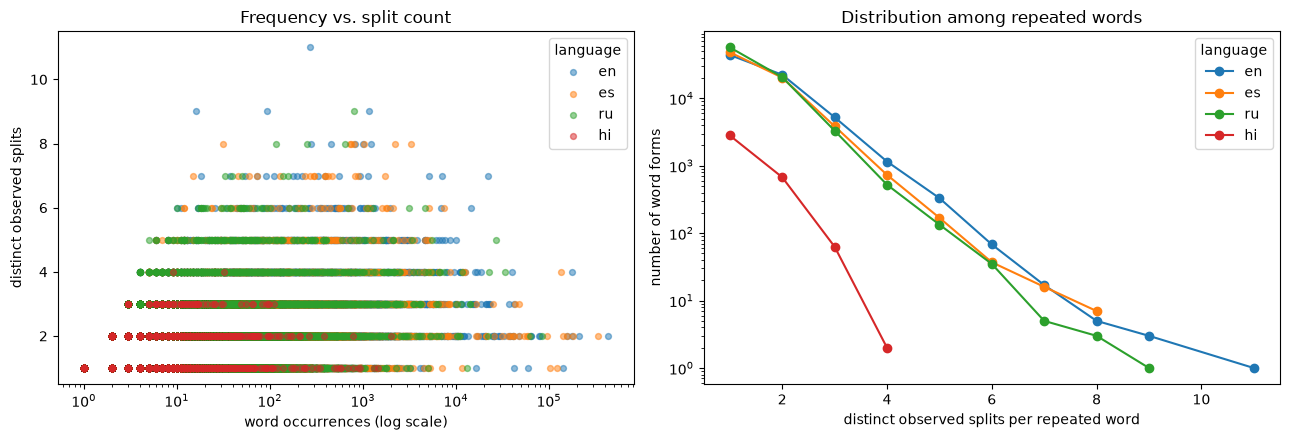

In [4]:
summary_dir = ROOT / 'results/global_voices_context_analysis/word_summaries'
summary_dir.mkdir(parents=True, exist_ok=True)
word_summaries = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for language in LANGUAGES:
    summary_path = summary_dir / f'{language}_word_summary.csv'
    if summary_path.exists():
        summary = pd.read_csv(summary_path)
    else:
        if not DATABASE_AVAILABLE:
            raise FileNotFoundError(f'Missing saved word summary: {summary_path}')
        summary = summarize_language_words(DATABASE_PATH, language)
        summary.to_csv(summary_path, index=False)
    word_summaries[language] = summary
    if summary.empty:
        continue
    axes[0].scatter(summary['occurrence_frequency'], summary['unique_segmentations'], s=18, alpha=.5, label=language)
    repeated = summary[summary['occurrence_frequency'] >= 2]
    distribution = repeated['unique_segmentations'].value_counts().sort_index()
    axes[1].plot(distribution.index, distribution.values, marker='o', label=language)
axes[0].set_xscale('log'); axes[0].set_xlabel('word occurrences (log scale)')
axes[0].set_ylabel('distinct observed splits'); axes[0].set_title('Frequency vs. split count')
axes[0].legend(title='language')
axes[1].set_xlabel('distinct observed splits per repeated word'); axes[1].set_ylabel('number of word forms')
axes[1].set_yscale('log'); axes[1].set_title('Distribution among repeated words'); axes[1].legend(title='language')
fig.tight_layout()


In [5]:
# For each language, list frequent repeated words with more than one observed split.
variable_words = []
for language in LANGUAGES:
    summary = word_summaries[language]
    candidates = summary[(summary['occurrence_frequency'] >= 2) & (summary['unique_segmentations'] > 1)]
    candidates = candidates.sort_values(['unique_segmentations', 'occurrence_frequency'], ascending=[False, False]).head(10)
    candidates.insert(0, 'language', language)
    variable_words.append(candidates)
variable_words = [frame for frame in variable_words if not frame.empty]
if variable_words:
    display(pd.concat(variable_words, ignore_index=True)[['language', 'word', 'occurrence_frequency', 'unique_segmentations']])


,language,word,occurrence_frequency,unique_segmentations
0,en,organizing,271,11
1,en,organizations,1161,9
2,en,murderers,93,9
3,en,freedomflotilla,16,9
4,en,organization,1230,8
5,en,organized,992,8
6,en,environmental,815,8
7,en,livejournal,454,8
8,en,referring,278,8
9,en,people,22125,7


## Example context-cluster results

These five examples were selected from the completed corpus because each appeared repeatedly with more than one split. They are exploratory examples, not a random sample of every word. A pure cluster contains one split pattern; a mixed cluster contains multiple patterns.

| Language | Word | Appearances (sentences) | Splits / context groups | Pure / mixed groups | Most common split |
|---|---|---:|---:|---:|---|
| English | `organizing` | 271 (270) | 11 / 11 | 0 / 11 | `organizing` (43.5%) |
| English | `political` | 6,872 (6,567) | 6 / 6 | 0 / 6 | `pol|itical` (84.6%) |
| Spanish | `censura` | 736 (702) | 8 / 8 | 0 / 8 | `censura` (93.3%) |
| Russian | `губернатор` | 50 (49) | 7 / 7 | 1 / 6 | `губерн|атор` (56.0%) |
| Hindi | `फोटो` | 32 (27) | 4 / 4 | 0 / 4 | `फोटो` (50.0%) |

In the English example, `organizing` was kept whole in “The last thing he was organizing was a protest march…” and split as `organizin|g` in “We shouldn’t spend our energy organizing people on the Internet…”. The groups still contained multiple split patterns. For `political`, all six context groups contained four to six splits; `pol|itical` remained dominant in every group, making up 74.4–87.6% of each group’s appearances. This suggests that these broad word-count context groups did not separate the split patterns for this word. It is an exploratory result for five examples, not a conclusion about every word or language.



An additional English check of `read` found 1,979 occurrences across 1,935 sentences. Its two observed forms were `read` (87.2%) and `R|ead` (12.8%). Both context groups contained both forms, with nearly identical shares, so this grouping did not show a split difference tied to the word’s pronunciation. The observed difference tracks capitalization. Its saved tables are in `results/global_voices_context_analysis/word_explorations/en/read_*`.

For Russian and Hindi, `[byte cuts: ...]` marks model boundaries in the UTF-8 byte input; a cut may fall inside a written character and is not a readable letter boundary.

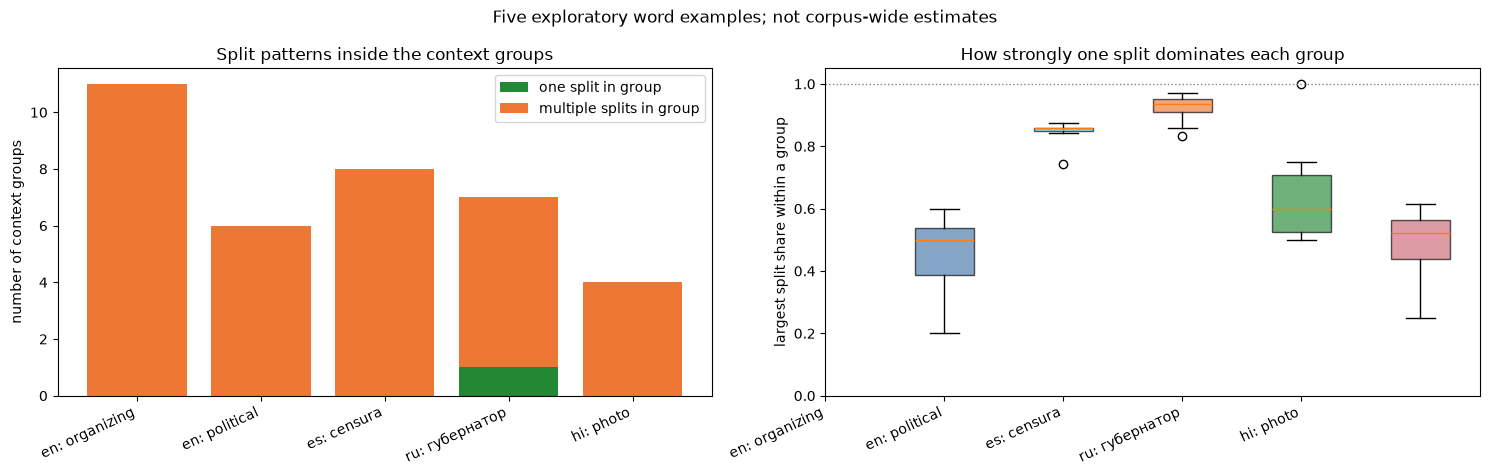

In [6]:
from pathlib import Path
import re
example_specs = [('en', 'organizing'), ('en', 'political'), ('es', 'censura'), ('ru', 'губернатор'), ('hi', 'फोटो')]
def example_slug(word):
    return ('u' + word.encode('utf-8').hex()) if any(ord(char) > 127 for char in word) else (re.sub(r'[^a-zA-Z0-9_-]+', '_', word).strip('_') or 'word')
example_clusters = []
for language, example_word in example_specs:
    path = ROOT / 'results/global_voices_context_analysis/word_explorations' / language / f'{example_slug(example_word)}_cluster_summary.csv'
    example_clusters.append((language, example_word, pd.read_csv(path)))
labels = [f'{language}: {example_word}' if language != 'hi' else 'hi: photo' for language, example_word, _ in example_clusters]
pure_counts = [int((summary['distinct_segmentations'] == 1).sum()) for _, _, summary in example_clusters]
mixed_counts = [int((summary['distinct_segmentations'] > 1).sum()) for _, _, summary in example_clusters]
colors = ['#4477aa', '#66ccee', '#ee7733', '#228833', '#cc6677']
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
x = np.arange(len(labels))
axes[0].bar(x, pure_counts, color='#228833', label='one split in group')
axes[0].bar(x, mixed_counts, bottom=pure_counts, color='#ee7733', label='multiple splits in group')
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, rotation=25, ha='right')
axes[0].set_ylabel('number of context groups'); axes[0].set_title('Split patterns inside the context groups')
axes[0].legend()
box = axes[1].boxplot([summary['dominant_segmentation_share'] for _, _, summary in example_clusters], patch_artist=True, showfliers=True)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=25, ha='right')
for patch, color in zip(box['boxes'], colors): patch.set_facecolor(color); patch.set_alpha(.65)
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel('largest split share within a group')
axes[1].set_title('How strongly one split dominates each group')
axes[1].tick_params(axis='x', labelrotation=25)
axes[1].axhline(1, color='gray', linestyle=':', linewidth=1)
fig.suptitle('Five exploratory word examples; not corpus-wide estimates')
fig.tight_layout()


### Additional word lookups

These eight examples are selected from the completed corpus; they are not a random sample. The automatic number of K-means groups equals the number of observed FlexiTokens split patterns. Pure/mixed counts cover K-means groups only. A sentence with no other pre-tokenized word is shown separately as an empty context.

| Language | Word | Occurrences (sentences) | Splits / K-means groups | Pure / mixed groups | Most common split | Largest split share within each group |
|---|---|---:|---:|---:|---|---:|
| English | `organizations` | 1,161 (1,142) | 9 / 9 | 0 / 9 | `organizat|ion|s` (55.6%) | 37.3–67.5% |
| English | `silence` | 552 (542) | 7 / 7 | 0 / 7 | `sil|ence` (94.6%) | 81.2–97.8% |
| Spanish | `política` | 3,319 (3,212) | 8 / 8 | 0 / 8 | `pol|ític|a` (57.2%) | 46.3–71.0% |
| Spanish | `esperanza` | 730 (721) | 8 / 8 | 0 / 8 | `esperanza` (61.8%) | 37.3–75.7% |
| Russian | `фотографии` | 797 (779) | 9 / 9 | 0 / 9 | internal byte cuts (63.6%) | 50.0–76.1% |
| Russian | `группа` | 698 (687) | 6 / 6 | 0 / 6 | internal byte cuts (42.0%) | 37.6–53.2% |
| Hindi | `साथ` | 110 (103) | 3 / 3 | 0 / 3 | whole word (73.6%) | 60.0–81.8% |
| Hindi | `लोगों` | 83 (81) | 3 / 3 | 1 / 2 | whole word (96.4%) | 85.7–100.0% |

For `política`, one sentence had no other word after removing the target, so it was kept as an empty context and not assigned to K-means. `silence` also had two such occurrences. For `लोगों`, one pure group contained 29 sentence contexts (30 appearances), all with the whole-word split; its other two groups were mixed. Many Russian and Hindi patterns include byte boundaries inside written characters, so they should not be read as ordinary letter splits. Across these eight selected words, 1 of 53 K-means groups was pure and 52 were mixed. The one pure group was for Hindi `लोगों` and contained 29 sentence contexts (30 appearances). This is a result for selected examples, not a corpus-wide rate. The `लोगों` group is a concrete case where one split was uniform in the observed contexts.


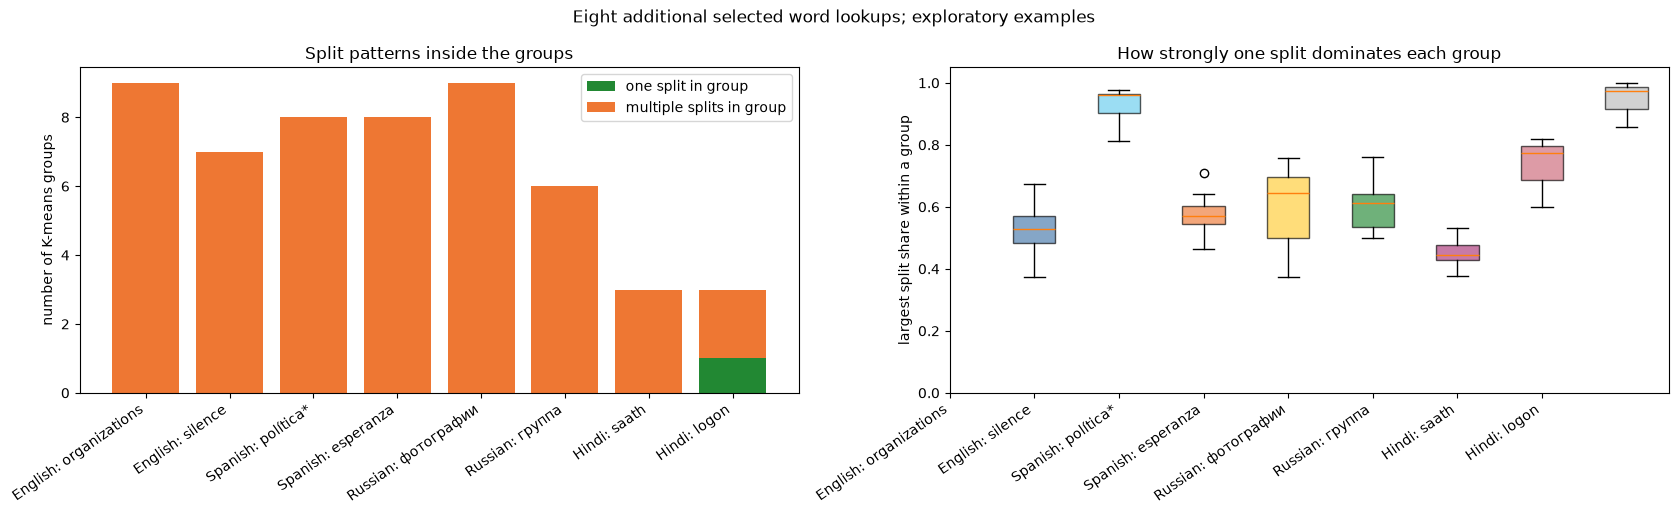

In [7]:
specs = [('en', 'organizations'), ('en', 'silence'), ('es', 'política'), ('es', 'esperanza'), ('ru', 'фотографии'), ('ru', 'группа'), ('hi', 'साथ'), ('hi', 'लोगों')]
def exploration_slug(word):
    return ('u' + word.encode('utf-8').hex()) if any(ord(char) > 127 for char in word) else word
additional_results = []
for language, word in specs:
    folder = ROOT / 'results/global_voices_context_analysis/word_explorations' / language
    summary = json.loads((folder / f'{exploration_slug(word)}_analysis_summary.json').read_text())
    clusters = pd.read_csv(folder / f'{exploration_slug(word)}_cluster_summary.csv')
    clusters = clusters[clusters.cluster != 'empty context']
    additional_results.append((language, word, summary, clusters))
labels = ['English: organizations', 'English: silence', 'Spanish: política*', 'Spanish: esperanza', 'Russian: фотографии', 'Russian: группа', 'Hindi: saath', 'Hindi: logon']
pure_counts = [int((clusters['distinct_segmentations'] == 1).sum()) for _, _, _, clusters in additional_results]
mixed_counts = [int((clusters['distinct_segmentations'] > 1).sum()) for _, _, _, clusters in additional_results]
fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
x = np.arange(len(labels))
axes[0].bar(x, pure_counts, color='#228833', label='one split in group')
axes[0].bar(x, mixed_counts, bottom=pure_counts, color='#ee7733', label='multiple splits in group')
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, rotation=35, ha='right')
axes[0].set_ylabel('number of K-means groups'); axes[0].set_title('Split patterns inside the groups'); axes[0].legend()
box = axes[1].boxplot([clusters['dominant_segmentation_share'] for _, _, _, clusters in additional_results], patch_artist=True, showfliers=True)
for patch, color in zip(box['boxes'], ['#4477aa', '#66ccee', '#ee7733', '#ffcc33', '#228833', '#aa3377', '#cc6677', '#bbbbbb']): patch.set_facecolor(color); patch.set_alpha(.65)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, rotation=35, ha='right')
axes[1].set_ylim(0, 1.05); axes[1].set_ylabel('largest split share within a group')
axes[1].set_title('How strongly one split dominates each group')
fig.suptitle('Eight additional selected word lookups; exploratory examples')
fig.tight_layout()


## Explore a word’s sentence contexts

The notebook includes the lookup code below. If the SQLite database is present, you can enter any word in a supported language and run the analysis. If it is not present, the cell can load one of the saved example words; a new word or custom number of context groups requires the database. The groups use the other words in the sentence, without using the target word’s split.

In automatic mode, the requested number of groups equals the number of observed splits. Changing the number of groups changes only the context grouping, not FlexiTokens’ output. If `ipywidgets` is unavailable, edit the variables in the final lookup cell and rerun it.


In [8]:
def load_saved_word_analysis(language, word, case_mode='lower', n_clusters=None):
    """Load a finished example from CSV when the large SQLite file is unavailable."""
    if case_mode != 'lower':
        raise ValueError('Saved examples are grouped in lowercase; exact-case lookup needs the SQLite database.')
    if n_clusters is not None:
        raise ValueError('Saved examples use automatic K-means group counts; a custom group count needs the SQLite database.')
    if any(ord(char) > 127 for char in word):
        slug = 'u' + word.encode('utf-8').hex()
    else:
        import re
        slug = re.sub(r'[^a-zA-Z0-9_-]+', '_', word).strip('_') or 'word'
    folder = RESULTS_DIR / 'word_explorations' / language
    required = ['contexts', 'pattern_counts', 'cluster_patterns', 'cluster_summary', 'similarity_sample']
    paths = {name: folder / f'{slug}_{name}.csv' for name in required}
    if not all(path.exists() for path in paths.values()):
        saved_words = sorted(path.name[:-len('_contexts.csv')] for path in folder.glob('*_contexts.csv'))
        raise FileNotFoundError(
            f'No saved analysis for {language}:{word}. This checkout has saved examples only; '
            'a new word requires analysis.sqlite3. Example file slugs: ' + ', '.join(saved_words)
        )
    contexts = pd.read_csv(paths['contexts'])
    for column in ('target_segmentations', 'target_spans', 'top_context_words'):
        contexts[column] = contexts[column].map(ast.literal_eval)
    pattern_counts = pd.read_csv(paths['pattern_counts'])
    cluster_patterns = pd.read_csv(paths['cluster_patterns'])
    cluster_summary = pd.read_csv(paths['cluster_summary'])
    similarity = pd.read_csv(paths['similarity_sample'], index_col=0)
    return {
        'language': language, 'query_word': word, 'case_mode': case_mode,
        'occurrence_count': int(contexts['target_occurrences'].sum()),
        'sentence_context_count': int(contexts['sentence_id'].nunique()),
        'unique_segmentation_count': int(pattern_counts['boundary_signature'].nunique()),
        'requested_clusters': int(pattern_counts['boundary_signature'].nunique()),
        'effective_clusters': int(cluster_summary['cluster'].nunique()),
        'cluster_count_note': 'Loaded the saved example analysis; no new clustering was run.',
        'feature_definition': 'Saved sentence contexts represented by counts of other words.',
        'clustering': 'Saved K-means output; split labels were evaluated after clustering.',
        'pattern_counts': pattern_counts, 'contexts': contexts,
        'cluster_patterns': cluster_patterns, 'cluster_summary': cluster_summary,
        'similarity': similarity,
        'vocabulary_size': None,
    }

def display_word_analysis(language, word, case_mode='lower', n_clusters=None):
    if DATABASE_AVAILABLE:
        result = analyze_word_contexts(DATABASE_PATH, language, word, case_mode, n_clusters)
    else:
        result = load_saved_word_analysis(language, word, case_mode, n_clusters)
    print(f"{language}: '{word}' appears {result['occurrence_count']} times across {result['sentence_context_count']} sentences and has {result['unique_segmentation_count']} distinct FlexiTokens splits.")
    print(f"Sentence contexts grouped: {result['effective_clusters']} groups (requested: {result['requested_clusters']}); the groups were formed from other words in the sentences, not from FlexiTokens splits.")
    if result['cluster_count_note']:
        print(result['cluster_count_note'])
    print('The heatmap shows each split pattern’s share within a context group. A group with one split pattern would have a single 100% cell; multiple nonzero cells mean the group contains multiple splits.')
    print('On the context map, dot color shows the FlexiTokens split; the dot outline and shaded area show the sentence-context group. The map compresses the full context vectors to two dimensions for display, so apparent distances are approximate.')
    display(result['pattern_counts'])
    display(result['cluster_summary'])
    display(result['cluster_patterns'])
    heat = result['cluster_patterns'].pivot(index='pattern_label', columns='cluster', values='occurrence_share').fillna(0)
    heat = heat.reindex(columns=sorted(heat.columns, key=lambda value: (value == 'empty context', int(value.split()[-1]) if value.startswith('cluster ') else 0)))
    fig, ax = plt.subplots(figsize=(max(8, 0.82 * len(heat.columns)), max(4, 0.38 * len(heat.index) + 2)))
    image = ax.imshow(heat.to_numpy(), aspect='auto', vmin=0, vmax=1, cmap='Blues')
    ax.set_xticks(range(len(heat.columns)), labels=heat.columns, rotation=45, ha='right')
    ax.set_yticks(range(len(heat.index)), labels=heat.index)
    ax.set_xlabel('sentence-context group'); ax.set_ylabel('FlexiTokens split pattern')
    ax.set_title(f'{word!r}: split shares within context groups')
    for row in range(len(heat.index)):
        for col in range(len(heat.columns)):
            value = heat.iat[row, col]
            if value > 0:
                ax.text(col, row, f'{value:.0%}', ha='center', va='center', fontsize=7,
                        color='white' if value >= .58 else 'black')
    fig.colorbar(image, ax=ax, label='share of occurrences in group', fraction=.04, pad=.03)
    fig.tight_layout(); plt.show()
    contexts = result['contexts'].copy()
    if not result['cluster_patterns'].empty:
        from matplotlib.lines import Line2D
        from matplotlib.patches import Patch
        from scipy.spatial import ConvexHull, QhullError
        pattern_table = result['pattern_counts'].sort_values('occurrence_count', ascending=False)
        signatures = pattern_table['boundary_signature'].tolist()
        pattern_names = dict(zip(pattern_table['boundary_signature'], pattern_table['segmentation_display']))
        cluster_names = sorted(contexts['cluster'].unique(), key=lambda value: (value == 'empty context', int(value.split()[-1]) if value.startswith('cluster ') else 0))
        cluster_palette = plt.get_cmap('tab10', max(1, len(cluster_names)))
        split_palette = plt.get_cmap('tab20', max(1, len(signatures)))
        cluster_colors = {name: cluster_palette(index) for index, name in enumerate(cluster_names)}
        split_colors = {signature: split_palette(index) for index, signature in enumerate(signatures)}
        occurrence_rows = []
        for _, row in contexts.iterrows():
            for span in row['target_spans']:
                occurrence_rows.append({'x': row['context_map_x'], 'y': row['context_map_y'],
                                       'cluster': row['cluster'], 'signature': span['boundary_signature']})
        occurrence_points = pd.DataFrame(occurrence_rows)
        fig, ax = plt.subplots(figsize=(14, 8))
        for cluster in cluster_names:
            sentence_points = (contexts.loc[contexts['cluster'] == cluster, ['context_map_x', 'context_map_y']]
                               .drop_duplicates().to_numpy(dtype=float))
            if len(sentence_points) >= 3 and np.linalg.matrix_rank(sentence_points - sentence_points.mean(axis=0)) == 2:
                try:
                    hull = ConvexHull(sentence_points)
                    polygon = sentence_points[hull.vertices]
                    polygon = np.vstack([polygon, polygon[0]])
                    ax.fill(polygon[:, 0], polygon[:, 1], color=cluster_colors[cluster], alpha=0.09, zorder=0)
                    ax.plot(polygon[:, 0], polygon[:, 1], color=cluster_colors[cluster], linewidth=1.0, alpha=0.65)
                except QhullError:
                    pass
        for (cluster, signature), group in occurrence_points.groupby(['cluster', 'signature'], sort=False):
            ax.scatter(group['x'], group['y'], s=58, color=[split_colors[signature]],
                       edgecolors=[cluster_colors[cluster]], linewidths=1.2, alpha=0.88, zorder=2)
        cluster_legend = [Patch(facecolor=cluster_colors[name], edgecolor=cluster_colors[name],
                                alpha=0.3, label=name) for name in cluster_names]
        split_legend = [Line2D([0], [0], marker='o', linestyle='', markersize=8,
                               markerfacecolor=split_colors[signature], markeredgecolor='black',
                               label=pattern_names[signature]) for signature in signatures]
        first_legend = ax.legend(handles=cluster_legend, title='Context cluster (shading)',
                                  loc='upper left', bbox_to_anchor=(1.01, 1), ncol=2,
                                  fontsize=8, title_fontsize=9, columnspacing=1.0)
        ax.add_artist(first_legend)
        ax.legend(handles=split_legend, title='FlexiTokens split (dot color)',
                  loc='lower left', bbox_to_anchor=(1.01, 0), ncol=2,
                  fontsize=8, title_fontsize=9, columnspacing=1.0)
        ax.set_xlabel('sentence-context dimension 1'); ax.set_ylabel('sentence-context dimension 2')
        ax.set_title(f'{word!r}: sentence contexts and observed FlexiTokens splits')
        ax.grid(alpha=0.18)
        fig.subplots_adjust(right=0.70, bottom=0.15)
        fig.text(0.08, 0.02, 'Each dot is a word occurrence. Clustering used the full context vectors; this 2D view and its shaded outlines are approximate, not exact cluster boundaries.', fontsize=8)
        plt.show()
    def mark_targets(row):
        sentence = row['sentence']
        for span in sorted(row['target_spans'], key=lambda item: item['char_start'], reverse=True):
            start, end = span['char_start'], span['char_end']
            label = f"⟦{span['surface_word']} → {span['segmentation_display']}⟧"
            sentence = sentence[:start] + label + sentence[end:]
        return sentence
    contexts['sentence_with_word_and_split'] = contexts.apply(mark_targets, axis=1)
    print('Example sentences (five per cluster; the export includes every context):')
    examples = contexts.groupby('cluster', group_keys=False).head(5)
    display(examples[['cluster', 'target_occurrences', 'top_context_words', 'sentence_with_word_and_split']])
    if not result['similarity'].empty:
        fig, ax = plt.subplots(figsize=(7, 6))
        image = ax.imshow(result['similarity'].to_numpy(), vmin=0, vmax=1, cmap='viridis')
        ax.set_title('Sentence-context cosine similarity (display sample)')
        ax.set_xlabel('sampled sentence'); ax.set_ylabel('sampled sentence')
        fig.colorbar(image, ax=ax, label='cosine similarity'); fig.tight_layout(); plt.show()
    return result

try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    language_widget = widgets.Dropdown(options=LANGUAGES, value='en', description='Language:')
    word_widget = widgets.Text(value='political', description='Word:')
    case_widget = widgets.Dropdown(options=['lower', 'exact'], value='lower', description='Match:')
    cluster_widget = widgets.IntText(value=0, description='Context groups (0=auto):')
    button = widgets.Button(description='Analyze', button_style='primary')
    output = widgets.Output()
    def on_analyze(_):
        with output:
            clear_output(wait=True)
            try:
                k = None if cluster_widget.value == 0 else cluster_widget.value
                display_word_analysis(language_widget.value, word_widget.value, case_widget.value, k)
            except Exception as error:
                print(type(error).__name__ + ':', error)
    button.on_click(on_analyze)
    display(widgets.VBox([language_widget, word_widget, case_widget, cluster_widget, button, output]))
except ImportError:
    print('ipywidgets is not installed; use the editable cell below.')

ipywidgets is not installed; use the editable cell below.


en: 'organizing' appears 271 times across 270 sentences and has 11 distinct FlexiTokens splits.
Sentence contexts grouped: 11 groups (requested: 11); the groups were formed from other words in the sentences, not from FlexiTokens splits.
The heatmap shows each split pattern’s share within a context group. A group with one split pattern would have a single 100% cell; multiple nonzero cells mean the group contains multiple splits.
On the context map, dot color shows the FlexiTokens split; the dot outline and shaded area show the sentence-context group. The map compresses the full context vectors to two dimensions for display, so apparent distances are approximate.


,boundary_signature,segmentation_display,occurrence_count,sentence_count,occurrence_percentage
0,none,organizing,118,118,43.542435
1,9,organizin|g,80,80,29.520295
2,"5,9",organ|izin|g,22,22,8.118081
3,"5,7,9",organ|iz|in|g,20,20,7.380074
4,"7,9",organiz|in|g,13,13,4.797048
5,"2,5,7,9",Or|gan|iz|in|g,11,11,4.059041
6,5,organ|izing,3,3,1.107011
7,7,Organiz|ing,1,1,0.369004
8,"2,9",or|ganizin|g,1,1,0.369004
9,"2,7",or|ganiz|ing,1,1,0.369004


,cluster,sentence_count,target_occurrence_count,distinct_segmentations,dominant_segmentation_share,dominant_segmentation_percentage
0,cluster 1,26,26,5,0.500000,50.000000
1,cluster 10,24,24,6,0.375000,37.500000
2,cluster 11,10,10,4,0.600000,60.000000
3,cluster 2,2,2,2,0.500000,50.000000
4,cluster 3,38,38,7,0.552632,55.263158
5,cluster 4,34,35,7,0.400000,40.000000
6,cluster 5,57,57,5,0.543860,54.385965
7,cluster 6,47,47,8,0.531915,53.191489
8,cluster 7,5,5,5,0.200000,20.000000
9,cluster 8,15,15,6,0.333333,33.333333


,cluster,boundary_signature,segmentation,pattern_label,occurrence_count,occurrence_share,sentence_count,target_occurrences_in_cluster
0,cluster 1,"2,5,7,9",or|gan|iz|in|g,"or|gan|iz|in|g [2,5,7,9]",2,0.076923,26,26
1,cluster 1,"5,7,9",organ|iz|in|g,"organ|iz|in|g [5,7,9]",3,0.115385,26,26
2,cluster 1,"7,9",Organiz|in|g,"Organiz|in|g [7,9]",1,0.038462,26,26
3,cluster 1,9,organizin|g,organizin|g [9],7,0.269231,26,26
4,cluster 1,none,organizing,organizing [none],13,0.500000,26,26
...,...,...,...,...,...,...,...,...
56,cluster 9,"5,7,9",organ|iz|in|g,"organ|iz|in|g [5,7,9]",1,0.083333,12,12
57,cluster 9,"5,9",organ|izin|g,"organ|izin|g [5,9]",1,0.083333,12,12
58,cluster 9,"7,9",organiz|in|g,"organiz|in|g [7,9]",1,0.083333,12,12
59,cluster 9,9,organizin|g,organizin|g [9],5,0.416667,12,12


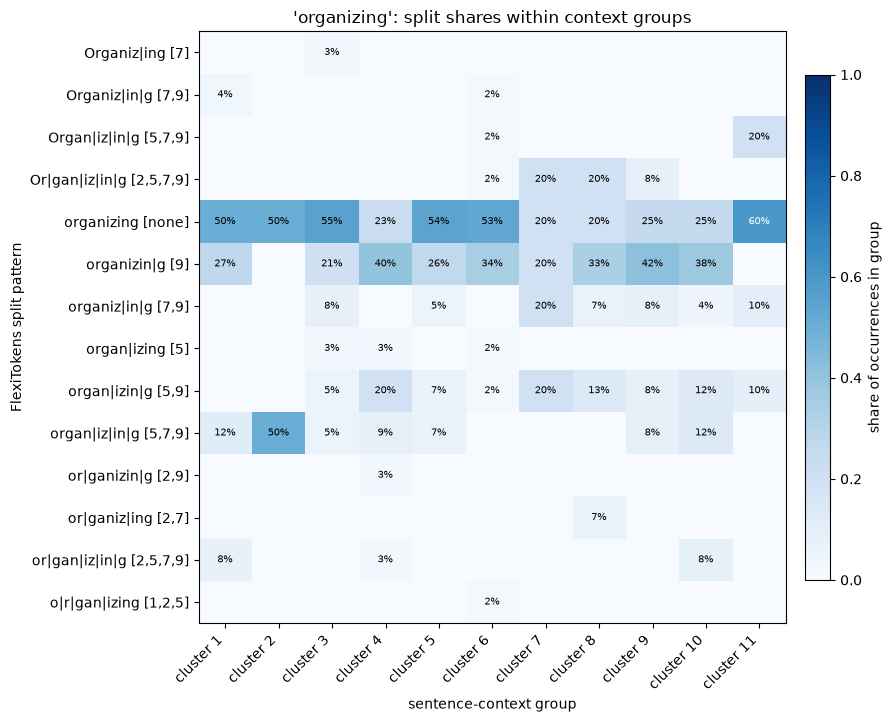

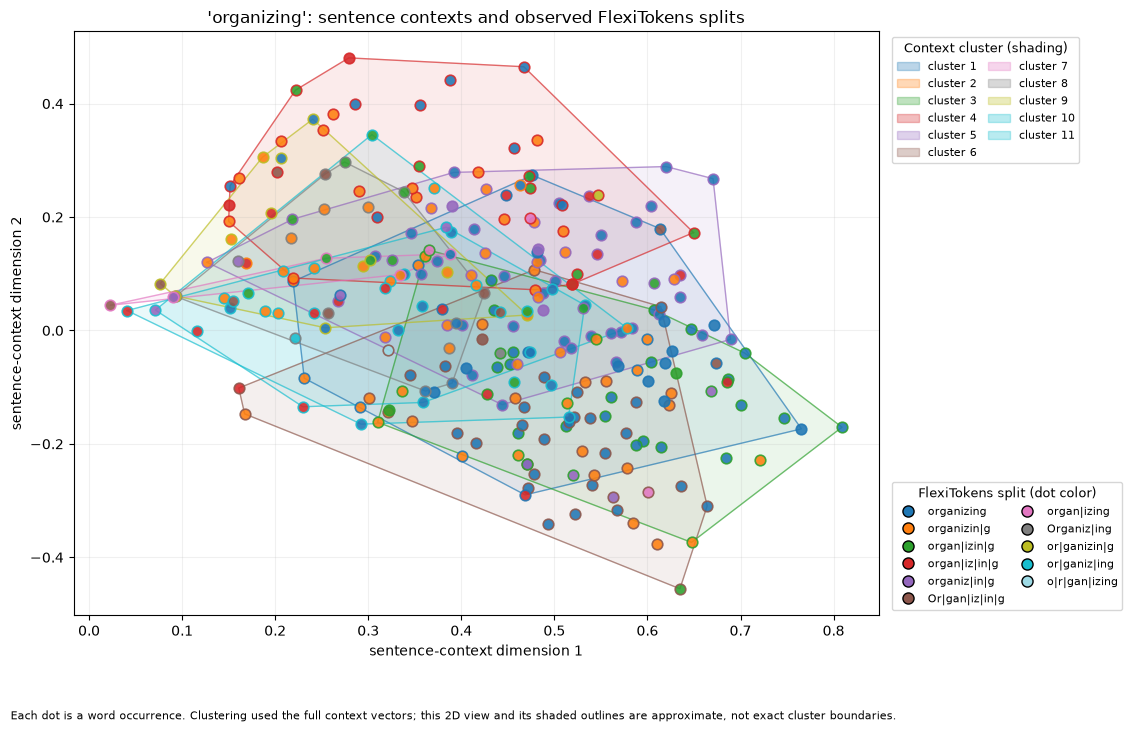

Example sentences (five per cluster; the export includes every context):


,cluster,target_occurrences,top_context_words,sentence_with_word_and_split
0,cluster 3,1,"[(was, 2), (the, 2), (a, 2), (to, 1), (thing, ...",The last thing he was ⟦organizing → organizing...
1,cluster 3,1,"[(the, 2), (was, 1), (two, 1), (trans, 1), (te...",The original text was presented by two groups:...
2,cluster 1,1,"[(t, 2), (we, 1), (this, 1), (the, 1), (spend,...",We shouldn’t spend our energy ⟦organizing → or...
3,cluster 5,1,"[(to, 5), (and, 4), (the, 4), (in, 3), (media,...",“It is an activity to discuss the current stat...
4,cluster 5,1,"[(the, 3), (and, 2), (sites, 2), (with, 1), (h...",Along with the more decisive offline ⟦organizi...
5,cluster 3,1,"[(the, 2), (youth, 1), (human, 1), (a, 1), (be...","Before I end, a youth leader threatened to hit..."
6,cluster 4,1,"[(and, 2), (vmro, 1), (has, 1), (accounts, 1),...",The Macedonian ruling party VMRO-DPMNE has a h...
7,cluster 3,1,"[(the, 6), (youth, 2), (by, 2), (of, 2), (a, 2...",On the same day the ⟦Organizing → Organizing⟧ ...
8,cluster 4,1,"[(egypt, 2), (food, 2), (jan25, 2), (trading, ...",Basic food hard to find #Egypt #Jan25 @MarcoMa...
9,cluster 4,1,"[(and, 2), (was, 1), (vital, 1), (because, 1),...",This event was unique to Nepali activism and p...


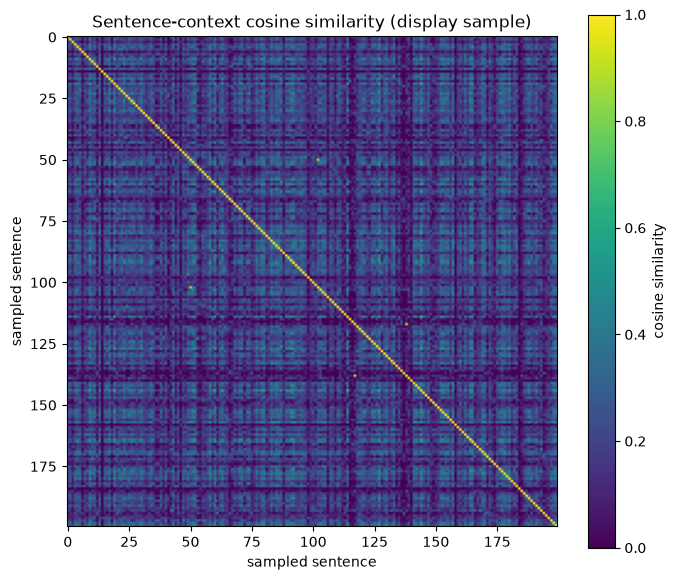

In [9]:
# Edit these values, then rerun this cell.
language = 'en'
word = 'organizing'
case_mode = 'lower'  # 'lower' groups capitalization; 'exact' keeps the spelling as written
n_clusters = None   # None uses one group per observed split pattern; or enter a different number of context groups
word_result = display_word_analysis(language, word, case_mode, n_clusters)


### Save this word’s tables

After a fresh analysis with the database available, run this cell to save the context assignments, split counts, cluster summaries, and sampled similarity matrix as CSV files.


In [10]:
import re
def export_word_result(result):
    if result is None:
        raise ValueError('Run a word analysis first and pass its returned result.')
    folder = ROOT / 'results/global_voices_context_analysis/word_explorations' / result['language']
    folder.mkdir(parents=True, exist_ok=True)
    word = result['query_word']
    slug = ('u' + word.encode('utf-8').hex()) if any(ord(char) > 127 for char in word) else (re.sub(r'[^a-zA-Z0-9_-]+', '_', word).strip('_') or 'word')
    for table_name in ['contexts', 'pattern_counts', 'cluster_patterns', 'cluster_summary']:
        result[table_name].to_csv(folder / f'{slug}_{table_name}.csv', index=False)
    result['similarity'].to_csv(folder / f'{slug}_similarity_sample.csv')
    print('saved word exploration to', folder)

# after running the editable cell above, use: export_word_result(word_result)

## Interpreting the output

- **Word appearances** count every occurrence of the selected spelling. **Sentence contexts** count the sentences it appears in; if the word appears twice in one sentence, that is two appearances but one context.
- **Observed splits** are the different FlexiTokens segmentations found for this spelling in the saved corpus.
- **Number of context groups** (often called *K*) controls how many groups K-means makes from the sentence contexts. With automatic selection, the requested group count is set to the number of observed splits. A manually entered count is only a comparison setting: it does not alter FlexiTokens’ output.
- K-means groups sentences using counts of the other words in each sentence; it does not see the target word’s split. The split-share heatmap and tables show how the observed splits are distributed across those groups. Each column is a context group, each row is a split pattern, and the cell color and percentage show that split’s share within the group. A single 100% cell means the group has one split; several nonzero cells mean it is mixed.
- In the cluster summary, **distinct segmentations** tells how many different splits occur in that group. **Dominant segmentation percentage** is the share of that group’s appearances that received its most common split. A group with one split is uniform in this sample; a group with several splits is mixed.
- `random_state=0` makes K-means start repeatably; it does not add randomness to FlexiTokens. The model’s boundaries use the saved deterministic 0.5 threshold.
- Each sentence contributes one context vector. If the target appears more than once in a sentence, all its occurrences share that context cluster, while the table still counts each split occurrence.
- If groups tend to contain different or more uniform splits, that is evidence of an association between these measured sentence contexts and the splits. Mixed splits mean these word-count features alone do not fully separate the observed patterns. This exploratory comparison does not show that context caused a split or reveal a word’s intended meaning.
- In the cluster map, each dot is a word occurrence; dot color identifies its split, while the outline and shaded region identify its context group. The 2D coordinates are an approximate projection of the full word-count vectors. The separate cosine-similarity heatmap shows at most 200 evenly sampled contexts; clustering uses all eligible contexts.
- The model predicts boundaries from left to right. These sentence vectors include words on both sides of the target, so this comparison does not establish that every counted word could influence a prediction.
- Byte-level splits inside a written character are shown with byte positions by the evaluator; do not read those as ordinary character splits.